# NLP Task 2: LLMs for AI Feedback

## 0. Setup and Dataset

In [1]:
%pip -q install langchain-deepseek pandas numpy scipy scikit-learn matplotlib tqdm

In [2]:
import os
import re
import json
import time
import copy
import random
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from google.colab import userdata
from langchain_deepseek import ChatDeepSeek
from scipy.stats import (
    chi2,
    binomtest,
    friedmanchisquare,
    wilcoxon,
    fisher_exact
)
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

### 0.1 Model and API Configuration

In [3]:
api_key = userdata.get("DEEPSEEK_API_KEY")

if not api_key:
    raise ValueError("Please add DEEPSEEK_API_KEY to Google Colab Secrets.")

os.environ["DEEPSEEK_API_KEY"] = api_key
os.environ["DEEPSEEK_BASE_URL"] = "https://api.deepseek.com/v1"

MODEL_NAME = "deepseek-chat"
BASE_TEMPERATURE = 0
SC_TEMPERATURE = 0.7
N_SC_VOTES = 5
RANDOM_SEED = 2026
FEW_SHOT_SEED = 42
N_FEW_SHOT = 4

llm = ChatDeepSeek(
    model=MODEL_NAME,
    temperature=BASE_TEMPERATURE
)

sc_llm = ChatDeepSeek(
    model=MODEL_NAME,
    temperature=SC_TEMPERATURE
)

agent_llm = ChatDeepSeek(
    model=MODEL_NAME,
    temperature=BASE_TEMPERATURE
)

coordinator_llm = ChatDeepSeek(
    model=MODEL_NAME,
    temperature=BASE_TEMPERATURE
)

print("Model:", MODEL_NAME)
print("Baseline / Few-shot / CoT temperature:", BASE_TEMPERATURE)
print("Self-Consistency temperature:", SC_TEMPERATURE)
print("Self-Consistency votes:", N_SC_VOTES)

Model: deepseek-chat
Baseline / Few-shot / CoT temperature: 0
Self-Consistency temperature: 0.7
Self-Consistency votes: 5


### 0.2 Load and Validate Dataset

In [4]:
DATA_URL = (
    "https://NLP-course-cuhksz.github.io/"
    "Assignments/Assignment1/task2/data/1.rlhf.jsonl"
)
DATA_PATH = Path("1.rlhf.jsonl")

if not DATA_PATH.exists():
    urlretrieve(DATA_URL, DATA_PATH)

with DATA_PATH.open("r", encoding="utf-8") as file:
    data = [
        json.loads(line)
        for line in file
        if line.strip()
    ]

required_fields = {"Question", "Answer1", "Answer2", "Preference"}
valid_labels = {"Answer1", "Answer2"}

if len(data) != 100:
    raise ValueError(f"Expected 100 samples, found {len(data)}.")

for index, item in enumerate(data, start=1):
    missing = required_fields - set(item.keys())
    if missing:
        raise ValueError(f"Sample {index} is missing fields: {missing}")

    if item["Preference"] not in valid_labels:
        raise ValueError(f"Invalid preference label in sample {index}.")

    for field in ["Question", "Answer1", "Answer2"]:
        if not isinstance(item[field], str) or not item[field].strip():
            raise ValueError(f"Empty or invalid {field} in sample {index}.")

preference_counts = pd.Series(
    [item["Preference"] for item in data]
).value_counts().reindex(
    ["Answer1", "Answer2"],
    fill_value=0
)

print("Total samples:", len(data))
print("Preference distribution:")
display(preference_counts.rename_axis("Preference").to_frame("Count"))

Total samples: 100
Preference distribution:


,Count
Preference,
Answer1,55
Answer2,45


### 0.3 Randomize Answer Order and Create the Evaluation Split

In [5]:
def swap_answer_label(label):
    if label == "Answer1":
        return "Answer2"
    if label == "Answer2":
        return "Answer1"
    return label


def map_prediction_to_original(prediction, was_swapped):
    if prediction not in valid_labels:
        return prediction
    return swap_answer_label(prediction) if was_swapped else prediction


n_swapped = len(data) // 2
swap_flags = [True] * n_swapped + [False] * (len(data) - n_swapped)
random.Random(RANDOM_SEED).shuffle(swap_flags)

randomized_data = []

for sample_id, (original_item, was_swapped) in enumerate(
    zip(data, swap_flags),
    start=1
):
    item = copy.deepcopy(original_item)
    original_preference = original_item["Preference"]

    if was_swapped:
        item["Answer1"], item["Answer2"] = (
            item["Answer2"],
            item["Answer1"]
        )
        item["Preference"] = swap_answer_label(original_preference)

    item["_sample_id"] = sample_id
    item["_original_preference"] = original_preference
    item["_was_swapped"] = was_swapped
    item["_answer_order"] = "Swapped" if was_swapped else "Original"
    randomized_data.append(item)

few_shot_rng = random.Random(FEW_SHOT_SEED)
few_shot_indices = []

for label in ["Answer1", "Answer2"]:
    candidates = [
        index
        for index, item in enumerate(randomized_data)
        if item["Preference"] == label
    ]

    if len(candidates) < N_FEW_SHOT // 2:
        raise ValueError(f"Not enough examples for {label} demonstrations.")

    few_shot_indices.extend(
        few_shot_rng.sample(candidates, N_FEW_SHOT // 2)
    )

few_shot_indices = sorted(few_shot_indices)
few_shot_index_set = set(few_shot_indices)

few_shot_examples = [
    randomized_data[index]
    for index in few_shot_indices
]

test_indices = [
    index
    for index in range(len(data))
    if index not in few_shot_index_set
]

test_data = [data[index] for index in test_indices]
test_randomized_data = [
    randomized_data[index]
    for index in test_indices
]

if len(test_data) != 96:
    raise ValueError(f"Expected 96 test samples, found {len(test_data)}.")

reference_ids = [
    item["_sample_id"]
    for item in test_randomized_data
]

order_distribution = pd.Series(
    [item["_answer_order"] for item in test_randomized_data]
).value_counts().reindex(
    ["Original", "Swapped"],
    fill_value=0
)

print("Original dataset:", len(data))
print("Few-shot demonstrations:", len(few_shot_examples))
print("Matched evaluation samples:", len(test_data))
print("Answer order in evaluation set:")
display(order_distribution.rename_axis("Answer Order").to_frame("Samples"))
print("Few-shot sample IDs:", [i + 1 for i in few_shot_indices])

data_split_metadata = pd.DataFrame([
    {
        "sample_id": item["_sample_id"],
        "split": (
            "Few-shot demonstration"
            if index in few_shot_index_set
            else "Evaluation"
        ),
        "answer_order": item["_answer_order"],
        "was_swapped": item["_was_swapped"],
        "original_preference": item["_original_preference"],
        "model_visible_preference": item["Preference"]
    }
    for index, item in enumerate(randomized_data)
])

Original dataset: 100
Few-shot demonstrations: 4
Matched evaluation samples: 96
Answer order in evaluation set:


,Samples
Answer Order,
Original,49
Swapped,47


Few-shot sample IDs: [7, 13, 84, 99]


## 1. Baseline Prompt

### 1.1 Prompt

In [6]:
def baseline_prompt(item):
    return f"""
You are an impartial AI response evaluator.

Compare two responses to the same question and predict
which response is more likely to be preferred by a human.

Evaluate:
1. Relevance to the question.
2. Factual correctness.
3. Helpfulness.
4. Clarity and completeness.
5. Safety and appropriateness.

Do not automatically prefer a longer answer.
Choose the response that better satisfies the user's needs.

Question:
{item['Question']}

Answer1:
{item['Answer1']}

Answer2:
{item['Answer2']}

Reply with exactly one label:
Answer1
or
Answer2
"""

### 1.2 Run Evaluation

In [7]:
def response_to_text(response):
    content = response.content

    if isinstance(content, list):
        parts = []
        for block in content:
            if isinstance(block, dict):
                parts.append(block.get("text", ""))
            else:
                parts.append(str(block))
        return " ".join(parts)

    return str(content)


def get_token_usage(response):
    usage = getattr(response, "usage_metadata", None)

    if not usage:
        metadata = getattr(response, "response_metadata", {}) or {}
        usage = (
            metadata.get("token_usage")
            or metadata.get("usage")
            or {}
        )

    if hasattr(usage, "model_dump"):
        usage = usage.model_dump()

    if not isinstance(usage, dict):
        usage = {}

    input_tokens = usage.get(
        "input_tokens",
        usage.get("prompt_tokens")
    )
    output_tokens = usage.get(
        "output_tokens",
        usage.get("completion_tokens")
    )
    total_tokens = usage.get("total_tokens")

    if (
        total_tokens is None
        and input_tokens is not None
        and output_tokens is not None
    ):
        total_tokens = input_tokens + output_tokens

    return input_tokens, output_tokens, total_tokens


def extract_answer_choice(raw_output):
    patterns = [
        r"(?im)^\s*Final choice\s*:\s*Answer\s*([12])\s*[.!]?\s*$",
        r"(?im)^\s*Answer\s*([12])\s*[.!]?\s*$"
    ]

    for pattern in patterns:
        matches = re.findall(pattern, raw_output)
        if matches:
            return "Answer" + matches[-1]

    return "Unparseable"


def sum_optional(values):
    if not values or any(
        value is None or pd.isna(value)
        for value in values
    ):
        return np.nan
    return sum(values)


def make_result_row(
    original_item,
    prompt_item,
    shuffled_prediction,
    latency,
    input_tokens,
    output_tokens,
    total_tokens,
    raw_output,
    error=None
):
    original_prediction = map_prediction_to_original(
        shuffled_prediction,
        prompt_item["_was_swapped"]
    )

    is_valid = original_prediction in valid_labels

    if is_valid:
        rejected_label = (
            "Answer2"
            if original_prediction == "Answer1"
            else "Answer1"
        )
        chosen_answer = original_item[original_prediction]
        rejected_answer = original_item[rejected_label]
    else:
        rejected_label = None
        chosen_answer = None
        rejected_answer = None

    return {
        "sample_id": prompt_item["_sample_id"],
        "human_preference": original_item["Preference"],
        "prediction": original_prediction,
        "shuffled_prediction": shuffled_prediction,
        "answer_order": prompt_item["_answer_order"],
        "was_swapped": prompt_item["_was_swapped"],
        "correct": original_prediction == original_item["Preference"],
        "valid_prediction": is_valid,
        "chosen_label": original_prediction if is_valid else None,
        "rejected_label": rejected_label,
        "chosen_answer": chosen_answer,
        "rejected_answer": rejected_answer,
        "latency_seconds": latency,
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
        "total_tokens": total_tokens,
        "raw_output": raw_output,
        "error": error
    }


def run_single_method(method_name, prompt_builder, model=llm):
    results = []

    for original_item, prompt_item in tqdm(
        zip(test_data, test_randomized_data),
        total=len(test_data),
        desc=method_name
    ):
        start_time = time.perf_counter()

        try:
            response = model.invoke(prompt_builder(prompt_item))
            raw_output = response_to_text(response)
            shuffled_prediction = extract_answer_choice(raw_output)
            input_tokens, output_tokens, total_tokens = get_token_usage(response)
            error_message = None

        except Exception as error:
            raw_output = f"{type(error).__name__}: {error}"
            shuffled_prediction = "API_ERROR"
            input_tokens = output_tokens = total_tokens = None
            error_message = raw_output

        latency = time.perf_counter() - start_time

        results.append(
            make_result_row(
                original_item,
                prompt_item,
                shuffled_prediction,
                latency,
                input_tokens,
                output_tokens,
                total_tokens,
                raw_output,
                error_message
            )
        )

    return pd.DataFrame(results)


def method_summary(method_name, results_df):
    return {
        "Method": method_name,
        "Samples": len(results_df),
        "Accuracy (%)": results_df["correct"].mean() * 100,
        "Valid Prediction Rate (%)": (
            results_df["valid_prediction"].mean() * 100
        ),
        "Average Latency (s)": results_df["latency_seconds"].mean(),
        "Average Tokens": results_df["total_tokens"].mean()
    }


def display_method_summary(method_name, results_df):
    display(
        pd.DataFrame([method_summary(method_name, results_df)]).round(4)
    )

### 1.3 Results

In [8]:
baseline_df = run_single_method(
    "Baseline",
    baseline_prompt,
    llm
)

display_method_summary("Baseline", baseline_df)

baseline_df.to_csv(
    "baseline_results.csv",
    index=False,
    encoding="utf-8-sig"
)

Baseline:   0%|          | 0/96 [00:00<?, ?it/s]

,Method,Samples,Accuracy (%),Valid Prediction Rate (%),Average Latency (s),Average Tokens
0,Baseline,96,61.4583,100.0,0.9885,246.1458


## 2. Few-shot Prompting

### 2.1 Prompt

In [9]:
def format_pair(item):
    return (
        f"Question: {item['Question']}\n"
        f"Answer1: {item['Answer1']}\n"
        f"Answer2: {item['Answer2']}"
    )


def build_few_shot_prompt(item):
    demonstrations = []

    for index, example in enumerate(few_shot_examples, start=1):
        demonstrations.append(
            f"Example {index}\n"
            f"{format_pair(example)}\n"
            f"Human preference: {example['Preference']}"
        )

    examples_text = "\n\n".join(demonstrations)

    return f"""
You are evaluating two AI responses to the same question.

Predict which response is more likely to be preferred by human annotators.
Consider relevance, helpfulness, correctness, clarity and safety.
Do not prefer a response only because it is longer.

Use the following labeled examples as guidance:

{examples_text}

Evaluate the new pair:

{format_pair(item)}

Reply with exactly one label:
Answer1
or
Answer2
"""

### 2.2 Run Evaluation

In [10]:
few_shot_df = run_single_method(
    "Few-shot",
    build_few_shot_prompt,
    llm
)

display_method_summary("Few-shot", few_shot_df)

few_shot_df.to_csv(
    "few_shot_results.csv",
    index=False,
    encoding="utf-8-sig"
)

Few-shot:   0%|          | 0/96 [00:00<?, ?it/s]

,Method,Samples,Accuracy (%),Valid Prediction Rate (%),Average Latency (s),Average Tokens
0,Few-shot,96,61.4583,100.0,1.0187,1073.1458


## 3. Chain-of-Thought Prompting

### 3.1 Prompt

In [11]:
def build_cot_prompt(item):
    return f"""
You are evaluating two AI responses to the same question.

Compare the responses using these steps:
1. Identify the user's main request.
2. Assess how directly each response addresses it.
3. Compare relevance, helpfulness and factual correctness.
4. Consider clarity, completeness and safety.
5. Decide which response better satisfies the user's needs.

Provide a brief rationale based on these criteria.
Do not automatically prefer a longer response.

Question:
{item['Question']}

Answer1:
{item['Answer1']}

Answer2:
{item['Answer2']}

On the final line, output exactly:
Final choice: Answer1
or
Final choice: Answer2
"""

### 3.2 Run Evaluation

In [12]:
cot_df = run_single_method(
    "Chain-of-Thought",
    build_cot_prompt,
    llm
)

display_method_summary("Chain-of-Thought", cot_df)

cot_df.to_csv(
    "cot_results.csv",
    index=False,
    encoding="utf-8-sig"
)

Chain-of-Thought:   0%|          | 0/96 [00:00<?, ?it/s]

,Method,Samples,Accuracy (%),Valid Prediction Rate (%),Average Latency (s),Average Tokens
0,Chain-of-Thought,96,66.6667,98.9583,2.5449,506.1458


## 4. Self-Consistency

### 4.1 Prompt

In [13]:
def build_sc_prompt(item):
    return f"""
You are evaluating two AI responses to the same question.

Predict which response is more likely to be preferred by human annotators.
Consider relevance, helpfulness, correctness, clarity, completeness and safety.
Do not automatically prefer a longer response.

Question:
{item['Question']}

Answer1:
{item['Answer1']}

Answer2:
{item['Answer2']}

Provide a brief rationale.
On the final line, output exactly:
Final choice: Answer1
or
Final choice: Answer2
"""

### 4.2 Run Evaluation

In [14]:
sc_results = []

for original_item, prompt_item in tqdm(
    zip(test_data, test_randomized_data),
    total=len(test_data),
    desc="Self-Consistency"
):
    start_time = time.perf_counter()
    shuffled_votes = []
    raw_outputs = []
    input_usage = []
    output_usage = []
    total_usage = []
    errors = []

    for _ in range(N_SC_VOTES):
        try:
            response = sc_llm.invoke(build_sc_prompt(prompt_item))
            raw_output = response_to_text(response)
            vote = extract_answer_choice(raw_output)
            input_tokens, output_tokens, total_tokens = get_token_usage(response)

        except Exception as error:
            raw_output = f"{type(error).__name__}: {error}"
            vote = "API_ERROR"
            input_tokens = output_tokens = total_tokens = None
            errors.append(raw_output)

        shuffled_votes.append(vote)
        raw_outputs.append(raw_output)
        input_usage.append(input_tokens)
        output_usage.append(output_tokens)
        total_usage.append(total_tokens)

    valid_votes = [
        vote
        for vote in shuffled_votes
        if vote in valid_labels
    ]

    count_answer1 = valid_votes.count("Answer1")
    count_answer2 = valid_votes.count("Answer2")

    if count_answer1 > count_answer2:
        shuffled_prediction = "Answer1"
    elif count_answer2 > count_answer1:
        shuffled_prediction = "Answer2"
    else:
        shuffled_prediction = "Unparseable"

    latency = time.perf_counter() - start_time
    raw_output = "\n---\n".join(raw_outputs)

    row = make_result_row(
        original_item,
        prompt_item,
        shuffled_prediction,
        latency,
        sum_optional(input_usage),
        sum_optional(output_usage),
        sum_optional(total_usage),
        raw_output,
        "; ".join(errors) if errors else None
    )

    original_votes = [
        map_prediction_to_original(
            vote,
            prompt_item["_was_swapped"]
        )
        for vote in shuffled_votes
    ]

    row.update({
        "votes_model_visible": " | ".join(shuffled_votes),
        "votes_original": " | ".join(original_votes),
        "vote_counts_answer1": count_answer1,
        "vote_counts_answer2": count_answer2,
        "valid_votes": len(valid_votes)
    })

    sc_results.append(row)

sc_df = pd.DataFrame(sc_results)

display_method_summary("Self-Consistency", sc_df)

sc_df.to_csv(
    "self_consistency_results.csv",
    index=False,
    encoding="utf-8-sig"
)

Self-Consistency:   0%|          | 0/96 [00:00<?, ?it/s]

,Method,Samples,Accuracy (%),Valid Prediction Rate (%),Average Latency (s),Average Tokens
0,Self-Consistency,96,63.5417,100.0,8.1026,1544.625


## 5. Multi-Agent Evaluation

### 5.1 Agent Roles

In [15]:
agent_roles = [
    (
        "Accuracy Evaluator",
        "Assess factual correctness, logical consistency and whether claims are supported."
    ),
    (
        "Helpfulness Evaluator",
        "Assess relevance, usefulness and how directly the response addresses the user's needs."
    ),
    (
        "Quality and Safety Evaluator",
        "Assess clarity, completeness, appropriate tone and safety."
    )
]

print("Independent evaluators:", len(agent_roles))
print("Coordinator: conditional review when the initial evaluations do not agree.")

Independent evaluators: 3
Coordinator: conditional review when the initial evaluations do not agree.


### 5.2 Prompts and Decision Rules

In [16]:
def build_agent_prompt(item, agent_name, focus):
    return f"""
You are an independent preference evaluator: {agent_name}.

Your primary evaluation focus:
{focus}

Compare both answers fairly. Consider the overall human preference,
while giving particular attention to your assigned focus.

Question:
{item['Question']}

Answer1:
{item['Answer1']}

Answer2:
{item['Answer2']}

Give a concise rationale.
On the final line, output exactly:
Final choice: Answer1
or
Final choice: Answer2
"""


def build_coordinator_prompt(item, agent_evaluations):
    evaluations_text = "\n\n".join(
        f"{name}:\n{output}"
        for name, output in agent_evaluations
    )

    return f"""
You are the Coordinator in a multi-agent preference evaluation system.

Independent evaluators assessed the same pair of answers.
Their outputs are intermediate observations, not ground truth.

Review their choices and rationales. Pay attention to:
1. Whether their judgments agree or disagree.
2. The evidence supporting each choice.
3. Which answer better satisfies the user's actual request.
4. Whether an evaluator overemphasized one criterion while neglecting overall helpfulness.

Do not automatically follow the majority. Make an independent final decision
after considering the available evaluator feedback.

Question:
{item['Question']}

Answer1:
{item['Answer1']}

Answer2:
{item['Answer2']}

Evaluator feedback:
{evaluations_text}

Provide a concise final rationale.
On the final line, output exactly:
Final choice: Answer1
or
Final choice: Answer2
"""


def coordinate_decision(item, agent_evaluations, model=coordinator_llm):
    start_time = time.perf_counter()

    try:
        response = model.invoke(
            build_coordinator_prompt(item, agent_evaluations)
        )
        raw_output = response_to_text(response)
        prediction = extract_answer_choice(raw_output)
        input_tokens, output_tokens, total_tokens = get_token_usage(response)
        error = None

    except Exception as exception:
        raw_output = f"{type(exception).__name__}: {exception}"
        prediction = "API_ERROR"
        input_tokens = output_tokens = total_tokens = None
        error = raw_output

    return {
        "prediction": prediction,
        "raw_output": raw_output,
        "latency_seconds": time.perf_counter() - start_time,
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
        "total_tokens": total_tokens,
        "error": error
    }


def choose_majority(votes):
    valid_votes = [
        vote
        for vote in votes
        if vote in valid_labels
    ]

    count_answer1 = valid_votes.count("Answer1")
    count_answer2 = valid_votes.count("Answer2")

    if count_answer1 >= 2 and count_answer1 > count_answer2:
        return "Answer1"

    if count_answer2 >= 2 and count_answer2 > count_answer1:
        return "Answer2"

    return "Unparseable"

### 5.3 Run Multi-Agent Workflow

In [17]:
multi_agent_results = []

for original_item, prompt_item in tqdm(
    zip(test_data, test_randomized_data),
    total=len(test_data),
    desc="Multi-Agent"
):
    sample_start = time.perf_counter()

    agent_votes_shuffled = []
    agent_raw_outputs = []
    agent_evaluations = []
    input_usage = []
    output_usage = []
    total_usage = []
    errors = []

    for agent_name, focus in agent_roles:
        try:
            response = agent_llm.invoke(
                build_agent_prompt(
                    prompt_item,
                    agent_name,
                    focus
                )
            )

            raw_output = response_to_text(response)
            vote = extract_answer_choice(raw_output)
            input_tokens, output_tokens, total_tokens = get_token_usage(response)

        except Exception as error:
            raw_output = f"{type(error).__name__}: {error}"
            vote = "API_ERROR"
            input_tokens = output_tokens = total_tokens = None
            errors.append(f"{agent_name}: {raw_output}")

        agent_votes_shuffled.append(vote)
        agent_raw_outputs.append(raw_output)
        agent_evaluations.append((agent_name, raw_output))
        input_usage.append(input_tokens)
        output_usage.append(output_tokens)
        total_usage.append(total_tokens)

    initial_unanimous = (
        len(agent_votes_shuffled) == 3
        and all(vote in valid_labels for vote in agent_votes_shuffled)
        and len(set(agent_votes_shuffled)) == 1
    )

    coordinator_used = not initial_unanimous
    coordinator_result = {
        "prediction": "Not Used",
        "raw_output": "",
        "latency_seconds": 0.0,
        "input_tokens": None,
        "output_tokens": None,
        "total_tokens": None,
        "error": None
    }

    if initial_unanimous:
        shuffled_prediction = agent_votes_shuffled[0]
        decision_source = "Unanimous agent agreement"

    else:
        coordinator_result = coordinate_decision(
            prompt_item,
            agent_evaluations
        )

        if coordinator_result["error"]:
            errors.append(
                "Coordinator: " + coordinator_result["error"]
            )

        if coordinator_result["prediction"] in valid_labels:
            shuffled_prediction = coordinator_result["prediction"]
            decision_source = "Coordinator review"
        else:
            shuffled_prediction = choose_majority(agent_votes_shuffled)

            if shuffled_prediction in valid_labels:
                decision_source = "Majority fallback"
            else:
                decision_source = "Unresolved"

    total_latency = time.perf_counter() - sample_start

    if coordinator_used:
        all_input_usage = input_usage + [coordinator_result["input_tokens"]]
        all_output_usage = output_usage + [coordinator_result["output_tokens"]]
        all_total_usage = total_usage + [coordinator_result["total_tokens"]]
    else:
        all_input_usage = input_usage
        all_output_usage = output_usage
        all_total_usage = total_usage

    raw_output = (
        "\n\n--- AGENT ---\n\n".join(agent_raw_outputs)
        + (
            "\n\n--- COORDINATOR ---\n\n"
            + coordinator_result["raw_output"]
            if coordinator_used
            else ""
        )
    )

    row = make_result_row(
        original_item,
        prompt_item,
        shuffled_prediction,
        total_latency,
        sum_optional(all_input_usage),
        sum_optional(all_output_usage),
        sum_optional(all_total_usage),
        raw_output,
        "; ".join(errors) if errors else None
    )

    agent_votes_original = [
        map_prediction_to_original(
            vote,
            prompt_item["_was_swapped"]
        )
        for vote in agent_votes_shuffled
    ]

    coordinator_original_prediction = map_prediction_to_original(
        coordinator_result["prediction"],
        prompt_item["_was_swapped"]
    )

    row.update({
        "agent_1": agent_votes_original[0],
        "agent_2": agent_votes_original[1],
        "agent_3": agent_votes_original[2],
        "agent_1_shuffled": agent_votes_shuffled[0],
        "agent_2_shuffled": agent_votes_shuffled[1],
        "agent_3_shuffled": agent_votes_shuffled[2],
        "agent_votes_original": " | ".join(agent_votes_original),
        "agent_votes_shuffled": " | ".join(agent_votes_shuffled),
        "initial_unanimous": initial_unanimous,
        "coordinator_used": coordinator_used,
        "coordinator_prediction": coordinator_original_prediction,
        "coordinator_shuffled_prediction": coordinator_result["prediction"],
        "coordinator_latency_seconds": coordinator_result["latency_seconds"],
        "decision_source": decision_source,
        "agent_raw_outputs": json.dumps(
            agent_raw_outputs,
            ensure_ascii=False
        ),
        "coordinator_raw_output": coordinator_result["raw_output"]
    })

    multi_agent_results.append(row)

multi_agent_df = pd.DataFrame(multi_agent_results)

display_method_summary("Multi-Agent", multi_agent_df)

multi_agent_df.to_csv(
    "multi_agent_results.csv",
    index=False,
    encoding="utf-8-sig"
)

Multi-Agent:   0%|          | 0/96 [00:00<?, ?it/s]

,Method,Samples,Accuracy (%),Valid Prediction Rate (%),Average Latency (s),Average Tokens
0,Multi-Agent,96,61.4583,100.0,5.3366,1142.5312


### 5.4 Compare All Methods

In [18]:
method_dfs = {
    "Baseline": baseline_df,
    "Few-shot": few_shot_df,
    "Chain-of-Thought": cot_df,
    "Self-Consistency": sc_df,
    "Multi-Agent": multi_agent_df
}

for method, results_df in method_dfs.items():
    if results_df["sample_id"].duplicated().any():
        raise ValueError(f"Duplicate sample IDs in {method}.")

    if set(results_df["sample_id"]) != set(reference_ids):
        raise ValueError(f"Evaluation samples do not match in {method}.")

method_comparison_rows = []

for method, results_df in method_dfs.items():
    token_coverage = results_df["total_tokens"].notna().mean() * 100
    total_tokens = (
        results_df["total_tokens"].sum()
        if results_df["total_tokens"].notna().all()
        else np.nan
    )

    method_comparison_rows.append({
        "Method": method,
        "Samples": len(results_df),
        "Accuracy (%)": results_df["correct"].mean() * 100,
        "Valid Prediction Rate (%)": (
            results_df["valid_prediction"].mean() * 100
        ),
        "Average Latency (s)": results_df["latency_seconds"].mean(),
        "Average Tokens": results_df["total_tokens"].mean(),
        "Token Usage Coverage (%)": token_coverage,
        "Total Tokens": total_tokens,
        "Correct per 1000 Tokens": (
            results_df["correct"].sum() / total_tokens * 1000
            if pd.notna(total_tokens) and total_tokens > 0
            else np.nan
        )
    })

method_comparison_df = pd.DataFrame(method_comparison_rows)

display(method_comparison_df.round(4))

,Method,Samples,Accuracy (%),Valid Prediction Rate (%),Average Latency (s),Average Tokens,Token Usage Coverage (%),Total Tokens,Correct per 1000 Tokens
0,Baseline,96,61.4583,100.0000,0.9885,246.1458,100.0,23630,2.4968
1,Few-shot,96,61.4583,100.0000,1.0187,1073.1458,100.0,103022,0.5727
2,Chain-of-Thought,96,66.6667,98.9583,2.5449,506.1458,100.0,48590,1.3171
3,Self-Consistency,96,63.5417,100.0000,8.1026,1544.6250,100.0,148284,0.4114
4,Multi-Agent,96,61.4583,100.0000,5.3366,1142.5312,100.0,109683,0.5379


### 5.5 Agent Workflow Analysis

In [19]:
decision_counts = (
    multi_agent_df["decision_source"]
    .value_counts()
    .reindex(
        [
            "Unanimous agent agreement",
            "Coordinator review",
            "Majority fallback",
            "Unresolved"
        ],
        fill_value=0
    )
)

coordinator_cases = multi_agent_df[
    multi_agent_df["coordinator_used"]
]

workflow_summary = pd.DataFrame([
    {
        "Measure": "Initial unanimous agreement rate (%)",
        "Value": multi_agent_df["initial_unanimous"].mean() * 100
    },
    {
        "Measure": "Coordinator escalation rate (%)",
        "Value": multi_agent_df["coordinator_used"].mean() * 100
    },
    {
        "Measure": "Coordinator valid decision rate (%)",
        "Value": (
            coordinator_cases["coordinator_prediction"]
            .isin(valid_labels).mean() * 100
            if len(coordinator_cases) else np.nan
        )
    },
    {
        "Measure": "Average coordinator latency (s)",
        "Value": (
            coordinator_cases["coordinator_latency_seconds"].mean()
            if len(coordinator_cases) else 0
        )
    },
    {
        "Measure": "Final valid prediction rate (%)",
        "Value": multi_agent_df["valid_prediction"].mean() * 100
    }
])

print("Decision sources:")
display(
    decision_counts.rename_axis("Decision Source").to_frame("Samples")
)

print("Workflow summary:")
display(workflow_summary.round(4))

Decision sources:


,Samples
Decision Source,
Unanimous agent agreement,69
Coordinator review,27
Majority fallback,0
Unresolved,0


Workflow summary:


,Measure,Value
0,Initial unanimous agreement rate (%),71.8750
1,Coordinator escalation rate (%),28.1250
2,Coordinator valid decision rate (%),100.0000
3,Average coordinator latency (s),1.8473
4,Final valid prediction rate (%),100.0000


## 6. Additional Analysis

### 6.1 Paired Error Analysis

In [20]:
cot_compare = cot_df[
    ["sample_id", "correct"]
].rename(columns={"correct": "cot_correct"})

multi_compare = multi_agent_df[
    ["sample_id", "correct"]
].rename(columns={"correct": "multi_agent_correct"})

paired_error_df = cot_compare.merge(
    multi_compare,
    on="sample_id",
    validate="one_to_one"
)

multi_only = int(
    (
        paired_error_df["multi_agent_correct"]
        & ~paired_error_df["cot_correct"]
    ).sum()
)

cot_only = int(
    (
        paired_error_df["cot_correct"]
        & ~paired_error_df["multi_agent_correct"]
    ).sum()
)

both_correct = int(
    (
        paired_error_df["cot_correct"]
        & paired_error_df["multi_agent_correct"]
    ).sum()
)

both_wrong = int(
    (
        ~paired_error_df["cot_correct"]
        & ~paired_error_df["multi_agent_correct"]
    ).sum()
)

discordant = multi_only + cot_only

mcnemar_p = (
    binomtest(
        multi_only,
        n=discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    if discordant else 1.0
)

paired_error_summary = pd.DataFrame([{
    "Matched Samples": len(paired_error_df),
    "Both Correct": both_correct,
    "Both Incorrect": both_wrong,
    "Multi-Agent Only Correct": multi_only,
    "CoT Only Correct": cot_only,
    "Exact McNemar p-value": mcnemar_p
}])

display(paired_error_summary.round(6))

,Matched Samples,Both Correct,Both Incorrect,Multi-Agent Only Correct,CoT Only Correct,Exact McNemar p-value
0,96,51,24,8,13,0.38331


### 6.2 Statistical Significance Testing

In [21]:
from itertools import combinations

def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(len(p_values), np.nan)

    valid_indices = np.where(np.isfinite(p_values))[0]

    if len(valid_indices) == 0:
        return adjusted

    order = valid_indices[np.argsort(p_values[valid_indices])]
    sorted_p = p_values[order]
    m = len(sorted_p)

    adjusted_sorted = np.maximum.accumulate(
        (m - np.arange(m)) * sorted_p
    )
    adjusted_sorted = np.minimum(adjusted_sorted, 1.0)
    adjusted[order] = adjusted_sorted

    return adjusted


def paired_bootstrap_ci(differences, n_boot=10000, seed=42):
    differences = np.asarray(differences, dtype=float)
    differences = differences[np.isfinite(differences)]

    if len(differences) == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)
    indices = rng.integers(
        0,
        len(differences),
        size=(n_boot, len(differences))
    )

    bootstrap_means = differences[indices].mean(axis=1)

    lower, upper = np.quantile(
        bootstrap_means,
        [0.025, 0.975]
    )

    return lower, upper


accuracy_matrix = pd.DataFrame({
    method: df.set_index("sample_id").loc[reference_ids]["correct"].astype(int)
    for method, df in method_dfs.items()
})

latency_matrix = pd.DataFrame({
    method: pd.to_numeric(
        df.set_index("sample_id").loc[reference_ids]["latency_seconds"],
        errors="coerce"
    )
    for method, df in method_dfs.items()
})

tokens_matrix = pd.DataFrame({
    method: pd.to_numeric(
        df.set_index("sample_id").loc[reference_ids]["total_tokens"],
        errors="coerce"
    )
    for method, df in method_dfs.items()
})

n = len(reference_ids)
k = len(method_dfs)

accuracy_values = accuracy_matrix.to_numpy()
row_sums = accuracy_values.sum(axis=1)
column_sums = accuracy_values.sum(axis=0)
grand_total = accuracy_values.sum()

denominator = (
    k * grand_total - np.square(row_sums).sum()
)

numerator = (
    (k - 1)
    * (k * np.square(column_sums).sum() - grand_total ** 2)
)

if denominator > 0:
    cochran_q = numerator / denominator
    cochran_p = chi2.sf(cochran_q, k - 1)
else:
    cochran_q = np.nan
    cochran_p = np.nan


def safe_friedman(matrix):
    complete = matrix.dropna()

    if len(complete) < 2:
        return np.nan, np.nan, len(complete), np.nan

    values = [
        complete[column].to_numpy()
        for column in complete.columns
    ]

    if all(
        np.allclose(values[0], values[index])
        for index in range(1, len(values))
    ):
        statistic, p_value = 0.0, 1.0
    else:
        result = friedmanchisquare(*values)
        statistic, p_value = result.statistic, result.pvalue

    effect_size = (
        statistic / (len(complete) * (len(values) - 1))
    )

    return statistic, p_value, len(complete), effect_size


latency_stat, latency_p, latency_n, latency_w = safe_friedman(
    latency_matrix
)

tokens_stat, tokens_p, tokens_n, tokens_w = safe_friedman(
    tokens_matrix
)

overall_tests = pd.DataFrame([
    {
        "Metric": "Accuracy",
        "Test": "Cochran's Q",
        "N": n,
        "Statistic": cochran_q,
        "p-value": cochran_p,
        "Effect Size": np.nan,
        "Effect Size Measure": "Not reported"
    },
    {
        "Metric": "Latency",
        "Test": "Friedman Test",
        "N": latency_n,
        "Statistic": latency_stat,
        "p-value": latency_p,
        "Effect Size": latency_w,
        "Effect Size Measure": "Kendall's W"
    },
    {
        "Metric": "Total Tokens",
        "Test": "Friedman Test",
        "N": tokens_n,
        "Statistic": tokens_stat,
        "p-value": tokens_p,
        "Effect Size": tokens_w,
        "Effect Size Measure": "Kendall's W"
    }
])

pairwise_rows = []

comparison_matrices = {
    "Accuracy": accuracy_matrix,
    "Latency": latency_matrix,
    "Total Tokens": tokens_matrix
}

for metric, matrix in comparison_matrices.items():
    for method_a, method_b in combinations(matrix.columns, 2):
        pair = matrix[[method_a, method_b]].dropna()
        a = pair[method_a].to_numpy()
        b = pair[method_b].to_numpy()
        differences = a - b

        if len(pair) == 0:
            p_value = np.nan
            ci_lower = ci_upper = mean_difference = np.nan

        elif metric == "Accuracy":
            a_only = int(((a == 1) & (b == 0)).sum())
            b_only = int(((a == 0) & (b == 1)).sum())
            discordant_pairs = a_only + b_only

            p_value = (
                binomtest(
                    a_only,
                    n=discordant_pairs,
                    p=0.5,
                    alternative="two-sided"
                ).pvalue
                if discordant_pairs else 1.0
            )

            mean_difference = differences.mean() * 100
            ci_lower, ci_upper = paired_bootstrap_ci(
                differences * 100
            )

        else:
            if np.allclose(differences, 0):
                p_value = 1.0
            else:
                p_value = wilcoxon(
                    a,
                    b,
                    alternative="two-sided",
                    zero_method="wilcox",
                    method="auto"
                ).pvalue

            mean_difference = differences.mean()
            ci_lower, ci_upper = paired_bootstrap_ci(differences)

        pairwise_rows.append({
            "Metric": metric,
            "Method A": method_a,
            "Method B": method_b,
            "N Paired": len(pair),
            "Mean Difference (A-B)": mean_difference,
            "95% CI Lower": ci_lower,
            "95% CI Upper": ci_upper,
            "p-value": p_value
        })

pairwise_results = pd.DataFrame(pairwise_rows)
pairwise_results["Holm-adjusted p"] = np.nan

for metric in pairwise_results["Metric"].unique():
    mask = pairwise_results["Metric"] == metric
    pairwise_results.loc[
        mask,
        "Holm-adjusted p"
    ] = holm_adjust(
        pairwise_results.loc[mask, "p-value"].to_numpy()
    )

pairwise_results["Significant"] = (
    pairwise_results["Holm-adjusted p"] < 0.05
)

print("Overall tests:")
display(overall_tests.round(6))

print("Pairwise comparisons:")
display(pairwise_results.round(6))

Overall tests:


,Metric,Test,N,Statistic,p-value,Effect Size,Effect Size Measure
0,Accuracy,Cochran's Q,96,1.920000,0.75047,NaN,Not reported
1,Latency,Friedman Test,96,364.141667,0.00000,0.948286,Kendall's W
2,Total Tokens,Friedman Test,96,338.125000,0.00000,0.880534,Kendall's W


Pairwise comparisons:


,Metric,Method A,Method B,N Paired,Mean Difference (A-B),95% CI Lower,95% CI Upper,p-value,Holm-adjusted p,Significant
0,Accuracy,Baseline,Few-shot,96,0.000000,-8.333333,8.333333,1.000000,1.000000,False
1,Accuracy,Baseline,Chain-of-Thought,96,-5.208333,-13.541667,3.125000,0.332306,1.000000,False
2,Accuracy,Baseline,Self-Consistency,96,-2.083333,-10.416667,6.250000,0.814529,1.000000,False
3,Accuracy,Baseline,Multi-Agent,96,0.000000,-8.333333,8.333333,1.000000,1.000000,False
4,Accuracy,Few-shot,Chain-of-Thought,96,-5.208333,-14.583333,4.166667,0.404873,1.000000,False
5,Accuracy,Few-shot,Self-Consistency,96,-2.083333,-13.541667,9.375000,0.855536,1.000000,False
6,Accuracy,Few-shot,Multi-Agent,96,0.000000,-10.416667,10.416667,1.000000,1.000000,False
7,Accuracy,Chain-of-Thought,Self-Consistency,96,3.125000,-5.208333,11.458333,0.607239,1.000000,False
8,Accuracy,Chain-of-Thought,Multi-Agent,96,5.208333,-4.166667,14.583333,0.383310,1.000000,False
9,Accuracy,Self-Consistency,Multi-Agent,96,2.083333,-6.250000,10.416667,0.814529,1.000000,False


### 6.3 Efficiency and Pareto Analysis

In [22]:
efficiency_df = method_comparison_df.copy()

token_objective_available = efficiency_df["Total Tokens"].notna().all()

pareto_objectives = [
    "Accuracy (%)",
    "Average Latency (s)"
]

if token_objective_available:
    pareto_objectives.append("Total Tokens")

pareto_flags = []

for index, current in efficiency_df.iterrows():
    dominated = False

    for other_index, other in efficiency_df.iterrows():
        if index == other_index:
            continue

        no_worse = (
            other["Accuracy (%)"] >= current["Accuracy (%)"]
            and other["Average Latency (s)"] <= current["Average Latency (s)"]
        )

        strictly_better = (
            other["Accuracy (%)"] > current["Accuracy (%)"]
            or other["Average Latency (s)"] < current["Average Latency (s)"]
        )

        if token_objective_available:
            no_worse = (
                no_worse
                and other["Total Tokens"] <= current["Total Tokens"]
            )
            strictly_better = (
                strictly_better
                or other["Total Tokens"] < current["Total Tokens"]
            )

        if no_worse and strictly_better:
            dominated = True
            break

    pareto_flags.append(not dominated)

efficiency_df["Pareto Optimal"] = pareto_flags
efficiency_df["Pareto Objectives"] = ", ".join(pareto_objectives)

display(
    efficiency_df.sort_values(
        "Accuracy (%)",
        ascending=False
    ).round(4)
)

,Method,Samples,Accuracy (%),Valid Prediction Rate (%),Average Latency (s),Average Tokens,Token Usage Coverage (%),Total Tokens,Correct per 1000 Tokens,Pareto Optimal,Pareto Objectives
2,Chain-of-Thought,96,66.6667,98.9583,2.5449,506.1458,100.0,48590,1.3171,True,"Accuracy (%), Average Latency (s), Total Tokens"
3,Self-Consistency,96,63.5417,100.0000,8.1026,1544.6250,100.0,148284,0.4114,False,"Accuracy (%), Average Latency (s), Total Tokens"
0,Baseline,96,61.4583,100.0000,0.9885,246.1458,100.0,23630,2.4968,True,"Accuracy (%), Average Latency (s), Total Tokens"
1,Few-shot,96,61.4583,100.0000,1.0187,1073.1458,100.0,103022,0.5727,False,"Accuracy (%), Average Latency (s), Total Tokens"
4,Multi-Agent,96,61.4583,100.0000,5.3366,1142.5312,100.0,109683,0.5379,False,"Accuracy (%), Average Latency (s), Total Tokens"


### 6.4 Leave-one-Agent-out Ablation Study

In [23]:
agent_columns = ["agent_1", "agent_2", "agent_3"]
agent_shuffled_columns = [
    "agent_1_shuffled",
    "agent_2_shuffled",
    "agent_3_shuffled"
]

ablation_conditions = {
    "Full Multi-Agent": None,
    "Without Accuracy Evaluator": [1, 2],
    "Without Helpfulness Evaluator": [0, 2],
    "Without Quality and Safety Evaluator": [0, 1]
}

prompt_items_by_id = {
    item["_sample_id"]: item
    for item in test_randomized_data
}

original_items_by_id = {
    index + 1: item
    for index, item in enumerate(data)
}

ablation_rows = []
ablation_prediction_rows = []

for condition, remaining_indices in ablation_conditions.items():
    condition_predictions = []
    coordinator_calls = 0
    pair_agreements = 0

    for _, record in tqdm(
        multi_agent_df.iterrows(),
        total=len(multi_agent_df),
        desc=condition
    ):
        sample_id = int(record["sample_id"])
        prompt_item = prompt_items_by_id[sample_id]
        original_item = original_items_by_id[sample_id]

        if remaining_indices is None:
            prediction = record["prediction"]
            coordinator_used = bool(record["coordinator_used"])
            pair_agreement = np.nan

        else:
            all_raw_outputs = json.loads(record["agent_raw_outputs"])

            remaining_votes = [
                record[agent_shuffled_columns[index]]
                for index in remaining_indices
            ]

            remaining_evaluations = [
                (
                    agent_roles[index][0],
                    all_raw_outputs[index]
                )
                for index in remaining_indices
            ]

            pair_agreement = (
                all(vote in valid_labels for vote in remaining_votes)
                and remaining_votes[0] == remaining_votes[1]
            )

            if pair_agreement:
                shuffled_prediction = remaining_votes[0]
                coordinator_used = False

            else:
                coordinator_result = coordinate_decision(
                    prompt_item,
                    remaining_evaluations
                )
                coordinator_used = True

                if coordinator_result["prediction"] in valid_labels:
                    shuffled_prediction = coordinator_result["prediction"]
                else:
                    shuffled_prediction = "Unparseable"

            prediction = map_prediction_to_original(
                shuffled_prediction,
                prompt_item["_was_swapped"]
            )

        coordinator_calls += int(coordinator_used)
        if pair_agreement is True:
            pair_agreements += 1

        condition_predictions.append({
            "sample_id": sample_id,
            "human_preference": original_item["Preference"],
            "prediction": prediction,
            "correct": prediction == original_item["Preference"],
            "valid_prediction": prediction in valid_labels,
            "coordinator_used": coordinator_used
        })

    condition_df = pd.DataFrame(condition_predictions)
    valid_mask = condition_df["valid_prediction"]

    overall_accuracy = condition_df["correct"].mean() * 100
    valid_rate = valid_mask.mean() * 100
    valid_accuracy = (
        condition_df.loc[valid_mask, "correct"].mean() * 100
        if valid_mask.any()
        else np.nan
    )

    if remaining_indices is None:
        agreement_rate = (
            multi_agent_df["initial_unanimous"].mean() * 100
        )
    else:
        agreement_rate = pair_agreements / len(condition_df) * 100

    ablation_rows.append({
        "Method": condition,
        "Overall Accuracy (%)": overall_accuracy,
        "Valid Prediction Rate (%)": valid_rate,
        "Accuracy on Valid Predictions (%)": valid_accuracy,
        "Initial Agreement Rate (%)": agreement_rate,
        "Coordinator Escalation Rate (%)": (
            coordinator_calls / len(condition_df) * 100
        ),
        "Correct Samples": int(condition_df["correct"].sum()),
        "Unresolved Samples": int((~valid_mask).sum())
    })

    condition_df["Method"] = condition
    ablation_prediction_rows.append(condition_df)

ablation_results = pd.DataFrame(ablation_rows)

full_accuracy = ablation_results.loc[
    ablation_results["Method"] == "Full Multi-Agent",
    "Overall Accuracy (%)"
].iloc[0]

ablation_results["Overall Accuracy Change (pp)"] = (
    ablation_results["Overall Accuracy (%)"] - full_accuracy
)

ablation_predictions = pd.concat(
    ablation_prediction_rows,
    ignore_index=True
)

display(ablation_results.round(4))

Full Multi-Agent:   0%|          | 0/96 [00:00<?, ?it/s]

Without Accuracy Evaluator:   0%|          | 0/96 [00:00<?, ?it/s]

Without Helpfulness Evaluator:   0%|          | 0/96 [00:00<?, ?it/s]

Without Quality and Safety Evaluator:   0%|          | 0/96 [00:00<?, ?it/s]

,Method,Overall Accuracy (%),Valid Prediction Rate (%),Accuracy on Valid Predictions (%),Initial Agreement Rate (%),Coordinator Escalation Rate (%),Correct Samples,Unresolved Samples,Overall Accuracy Change (pp)
0,Full Multi-Agent,61.4583,100.0,61.4583,71.8750,28.1250,59,0,0.0000
1,Without Accuracy Evaluator,63.5417,100.0,63.5417,82.2917,17.7083,61,0,2.0833
2,Without Helpfulness Evaluator,62.5000,100.0,62.5000,86.4583,13.5417,60,0,1.0417
3,Without Quality and Safety Evaluator,65.6250,100.0,65.6250,75.0000,25.0000,63,0,4.1667


### 6.5 Answer Order Bias Analysis

In [24]:
order_df = pd.DataFrame({
    "sample_id": [
        item["_sample_id"]
        for item in test_randomized_data
    ],
    "Answer Order": [
        item["_answer_order"]
        for item in test_randomized_data
    ]
})

order_rows = []

for method, results_df in method_dfs.items():
    temp = results_df[
        ["sample_id", "correct"]
    ].merge(
        order_df,
        on="sample_id",
        how="left",
        validate="one_to_one"
    )

    original = temp[temp["Answer Order"] == "Original"]
    swapped = temp[temp["Answer Order"] == "Swapped"]

    contingency = [
        [
            int(original["correct"].sum()),
            int(len(original) - original["correct"].sum())
        ],
        [
            int(swapped["correct"].sum()),
            int(len(swapped) - swapped["correct"].sum())
        ]
    ]

    _, p_value = fisher_exact(contingency)

    order_rows.append({
        "Method": method,
        "Original Samples": len(original),
        "Original Accuracy (%)": original["correct"].mean() * 100,
        "Swapped Samples": len(swapped),
        "Swapped Accuracy (%)": swapped["correct"].mean() * 100,
        "Difference (Swapped - Original, pp)": (
            swapped["correct"].mean()
            - original["correct"].mean()
        ) * 100,
        "p-value": p_value
    })

order_results = pd.DataFrame(order_rows)
order_results["Holm-adjusted p"] = holm_adjust(
    order_results["p-value"].to_numpy()
)
order_results["Significant"] = (
    order_results["Holm-adjusted p"] < 0.05
)

print("Answer order distribution:")
display(
    order_df["Answer Order"]
    .value_counts()
    .rename_axis("Answer Order")
    .to_frame("Samples")
)

display(order_results.round(4))

Answer order distribution:


,Samples
Answer Order,
Original,49
Swapped,47


,Method,Original Samples,Original Accuracy (%),Swapped Samples,Swapped Accuracy (%),"Difference (Swapped - Original, pp)",p-value,Holm-adjusted p,Significant
0,Baseline,49,57.1429,47,65.9574,8.8146,0.4078,1.0,False
1,Few-shot,49,61.2245,47,61.7021,0.4776,1.0000,1.0,False
2,Chain-of-Thought,49,65.3061,47,68.0851,2.7790,0.8305,1.0,False
3,Self-Consistency,49,65.3061,47,61.7021,-3.6040,0.8325,1.0,False
4,Multi-Agent,49,55.1020,47,68.0851,12.9831,0.2139,1.0,False


### 6.6 Classification Performance

In [25]:
classification_rows = []
per_class_rows = []
confusion_rows = []

class_labels = ["Answer1", "Answer2"]
predicted_labels = ["Answer1", "Answer2", "Unparseable"]

for method, results_df in method_dfs.items():
    aligned_df = (
        results_df
        .set_index("sample_id")
        .loc[reference_ids]
    )

    y_true = aligned_df["human_preference"].astype(str)
    y_pred = aligned_df["prediction"].where(
        aligned_df["prediction"].isin(class_labels),
        "Unparseable"
    ).astype(str)

    accuracy = accuracy_score(y_true, y_pred)

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0
        )
    )

    _, _, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0
        )
    )

    classification_rows.append({
        "Method": method,
        "Samples": len(y_true),
        "Accuracy (%)": accuracy * 100,
        "Valid Prediction Rate (%)": (
            y_pred.isin(class_labels).mean() * 100
        ),
        "Macro Precision (%)": macro_precision * 100,
        "Macro Recall (%)": macro_recall * 100,
        "Macro F1 (%)": macro_f1 * 100,
        "Weighted F1 (%)": weighted_f1 * 100
    })

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=class_labels,
            average=None,
            zero_division=0
        )
    )

    for index, label in enumerate(class_labels):
        per_class_rows.append({
            "Method": method,
            "Class": label,
            "Precision (%)": precision[index] * 100,
            "Recall (%)": recall[index] * 100,
            "F1-score (%)": f1[index] * 100,
            "Support": support[index]
        })

    for actual_label in class_labels:
        for predicted_label in predicted_labels:
            count = int(
                (
                    (y_true == actual_label)
                    & (y_pred == predicted_label)
                ).sum()
            )

            confusion_rows.append({
                "Method": method,
                "Actual": actual_label,
                "Predicted": predicted_label,
                "Count": count
            })

classification_results = pd.DataFrame(classification_rows)
per_class_results = pd.DataFrame(per_class_rows)
confusion_results = pd.DataFrame(confusion_rows)

print("Overall classification metrics:")
display(classification_results.round(4))

print("Per-class metrics:")
display(per_class_results.round(4))

print("Confusion matrix counts:")
display(confusion_results)

Overall classification metrics:


,Method,Samples,Accuracy (%),Valid Prediction Rate (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%)
0,Baseline,96,61.4583,100.0000,60.5386,59.9206,59.8871,60.8794
1,Few-shot,96,61.4583,100.0000,61.1111,61.2434,61.1166,61.5722
2,Chain-of-Thought,96,66.6667,98.9583,66.9152,65.6085,66.0940,66.7608
3,Self-Consistency,96,63.5417,100.0000,62.9047,62.8307,62.8606,63.4893
4,Multi-Agent,96,61.4583,100.0000,61.1111,61.2434,61.1166,61.5722


Per-class metrics:


,Method,Class,Precision (%),Recall (%),F1-score (%),Support
0,Baseline,Answer1,63.9344,72.2222,67.8261,54
1,Baseline,Answer2,57.1429,47.6190,51.9481,42
2,Few-shot,Answer1,66.6667,62.9630,64.7619,54
3,Few-shot,Answer2,55.5556,59.5238,57.4713,42
4,Chain-of-Thought,Answer1,68.9655,74.0741,71.4286,54
5,Chain-of-Thought,Answer2,64.8649,57.1429,60.7595,42
6,Self-Consistency,Answer1,67.2727,68.5185,67.8899,54
7,Self-Consistency,Answer2,58.5366,57.1429,57.8313,42
8,Multi-Agent,Answer1,66.6667,62.9630,64.7619,54
9,Multi-Agent,Answer2,55.5556,59.5238,57.4713,42


Confusion matrix counts:


,Method,Actual,Predicted,Count
0,Baseline,Answer1,Answer1,39
1,Baseline,Answer1,Answer2,15
2,Baseline,Answer1,Unparseable,0
3,Baseline,Answer2,Answer1,22
4,Baseline,Answer2,Answer2,20
5,Baseline,Answer2,Unparseable,0
6,Few-shot,Answer1,Answer1,34
7,Few-shot,Answer1,Answer2,20
8,Few-shot,Answer1,Unparseable,0
9,Few-shot,Answer2,Answer1,17


### 6.7 Representative Case Studies

In [26]:
method_frames = method_dfs.copy()

case_table = baseline_df[
    ["sample_id", "human_preference", "answer_order"]
].copy()

for method, results_df in method_frames.items():
    temp = results_df[
        ["sample_id", "prediction"]
    ].rename(columns={"prediction": method})

    case_table = case_table.merge(
        temp,
        on="sample_id",
        how="inner",
        validate="one_to_one"
    )

prediction_columns = list(method_frames.keys())

case_table["correct_count"] = case_table.apply(
    lambda row: sum(
        row[method] == row["human_preference"]
        for method in prediction_columns
    ),
    axis=1
)

case_table["prediction_diversity"] = (
    case_table[prediction_columns].nunique(axis=1)
)

consensus_pool = case_table[
    (case_table["correct_count"] == len(prediction_columns))
    & (case_table["prediction_diversity"] == 1)
]

preferred_case1 = consensus_pool[
    consensus_pool["sample_id"] == 2
]

if not preferred_case1.empty:
    case1 = preferred_case1.iloc[0]
elif not consensus_pool.empty:
    case1 = consensus_pool.sort_values("sample_id").iloc[0]
else:
    case1 = case_table.sort_values(
        ["correct_count", "prediction_diversity", "sample_id"],
        ascending=[False, True, True]
    ).iloc[0]

disagreement_pool = case_table[
    (case_table["prediction_diversity"] > 1)
    & (case_table["correct_count"].between(1, len(prediction_columns) - 1))
].copy()

preferred_case2 = disagreement_pool[
    disagreement_pool["sample_id"] == 4
]

if not preferred_case2.empty:
    case2 = preferred_case2.iloc[0]
elif not disagreement_pool.empty:
    disagreement_pool["vote_balance"] = disagreement_pool[
        prediction_columns
    ].apply(
        lambda row: min(
            (row == "Answer1").sum(),
            (row == "Answer2").sum()
        ),
        axis=1
    )

    case2 = disagreement_pool.sort_values(
        ["vote_balance", "correct_count", "sample_id"],
        ascending=[False, True, True]
    ).iloc[0]
else:
    case2 = case_table.sort_values(
        ["prediction_diversity", "sample_id"],
        ascending=[False, True]
    ).iloc[0]


def show_case(row, title):
    sample_id = int(row["sample_id"])
    original_item = data[sample_id - 1]
    prompt_item = randomized_data[sample_id - 1]

    print("\n" + "=" * 75)
    print(title)
    print("=" * 75)
    print("Sample ID:", sample_id)
    print("Answer order:", prompt_item["_answer_order"])

    print("\nQuestion:")
    print(original_item["Question"])

    print("\nOriginal answers:")
    print("Original Answer1:", original_item["Answer1"])
    print("Original Answer2:", original_item["Answer2"])

    print("\nAnswers shown to the models:")
    print("Model-visible Answer1:", prompt_item["Answer1"])
    print("Model-visible Answer2:", prompt_item["Answer2"])

    print("\nGround truth:")
    print("Original label:", original_item["Preference"])
    print("Model-visible label:", prompt_item["Preference"])

    print("\nPredictions:")
    for method, results_df in method_frames.items():
        record = results_df.loc[
            results_df["sample_id"] == sample_id
        ].iloc[0]

        print(
            f"{method}: model-visible={record['shuffled_prediction']} | "
            f"original={record['prediction']} | "
            f"correct={record['correct']}"
        )

        if method == "Self-Consistency":
            print("  Votes:", record["votes_original"])

        if method == "Multi-Agent":
            print("  Agent votes:", record["agent_votes_original"])
            print("  Coordinator used:", record["coordinator_used"])
            print("  Decision source:", record["decision_source"])

    cot_record = cot_df.loc[
        cot_df["sample_id"] == sample_id
    ].iloc[0]

    multi_record = multi_agent_df.loc[
        multi_agent_df["sample_id"] == sample_id
    ].iloc[0]

    print("\nCoT rationale:")
    print(str(cot_record["raw_output"])[:2500])

    print("\nMulti-Agent evaluations:")
    print(str(multi_record["agent_raw_outputs"])[:3500])

    if multi_record["coordinator_used"]:
        print("\nCoordinator review:")
        print(str(multi_record["coordinator_raw_output"])[:2500])


case1_type = (
    "Consensus"
    if (
        case1["correct_count"] == len(prediction_columns)
        and case1["prediction_diversity"] == 1
    )
    else "Highest Agreement"
)

case2_type = (
    "Disagreement"
    if case2["prediction_diversity"] > 1
    else "Most Representative Available"
)

show_case(case1, f"CASE 1: {case1_type.upper()} CASE")
show_case(case2, f"CASE 2: {case2_type.upper()} CASE")

representative_cases = pd.DataFrame([
    {
        "Case": case1_type,
        "Sample ID": int(case1["sample_id"]),
        "Correct Methods": int(case1["correct_count"]),
        "Prediction Diversity": int(case1["prediction_diversity"])
    },
    {
        "Case": case2_type,
        "Sample ID": int(case2["sample_id"]),
        "Correct Methods": int(case2["correct_count"]),
        "Prediction Diversity": int(case2["prediction_diversity"])
    }
])

display(representative_cases)


CASE 1: CONSENSUS CASE
Sample ID: 5
Answer order: Swapped

Question:
Human: Can you list some Caribbean countries that use French as their official language?

Original answers:
Original Answer1: Assistant: Haiti, Martinique, Guadeloupe, Saint Lucia, and Saint Vincent and the Grenadines all use French as their official language.  The Dominican Republic also has a large Haitian immigrant population.
Original Answer2: Assistant: Sure, the largest country is Haiti, and the official language is French.  Then you've got the French-speaking island nations of Martinique and Guadeloupe, and also the partially French-speaking island nation of Saint Lucia.

Answers shown to the models:
Model-visible Answer1: Assistant: Sure, the largest country is Haiti, and the official language is French.  Then you've got the French-speaking island nations of Martinique and Guadeloupe, and also the partially French-speaking island nation of Saint Lucia.
Model-visible Answer2: Assistant: Haiti, Martinique, Guad

,Case,Sample ID,Correct Methods,Prediction Diversity
0,Consensus,5,5,1
1,Disagreement,4,3,2


### 6.8 Visualizations

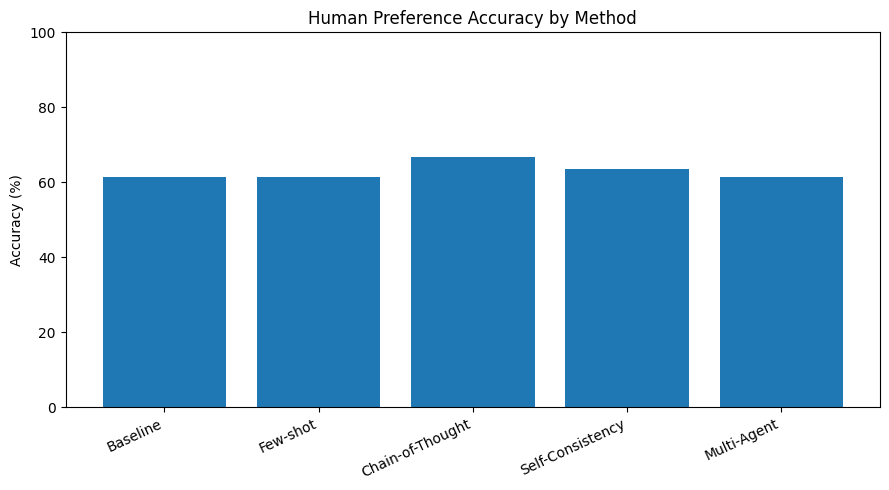

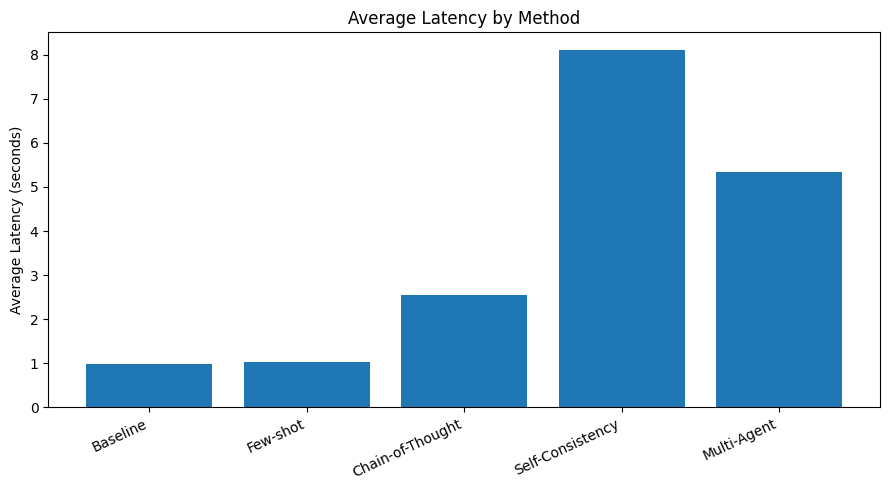

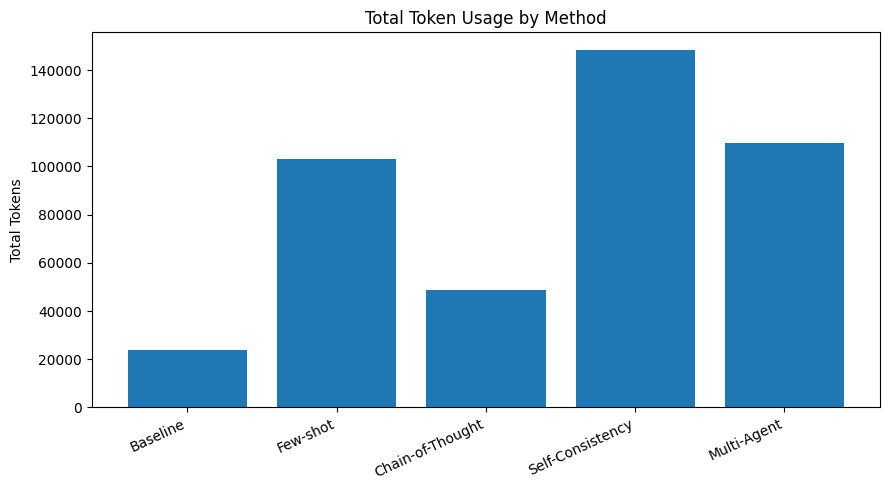

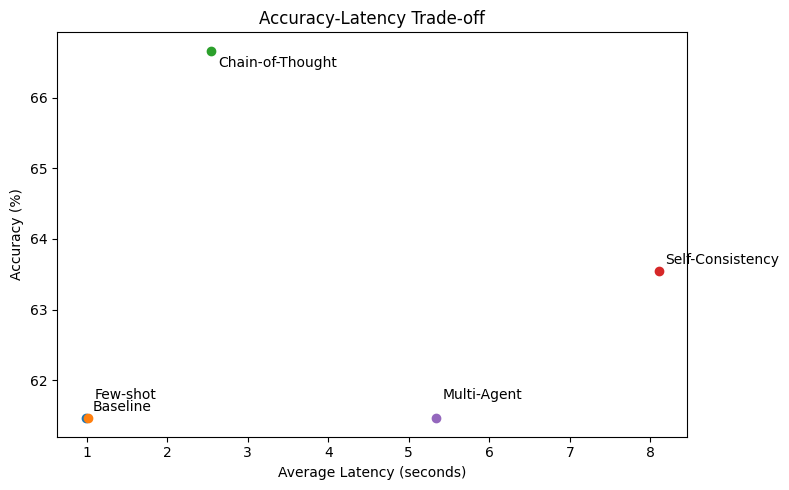

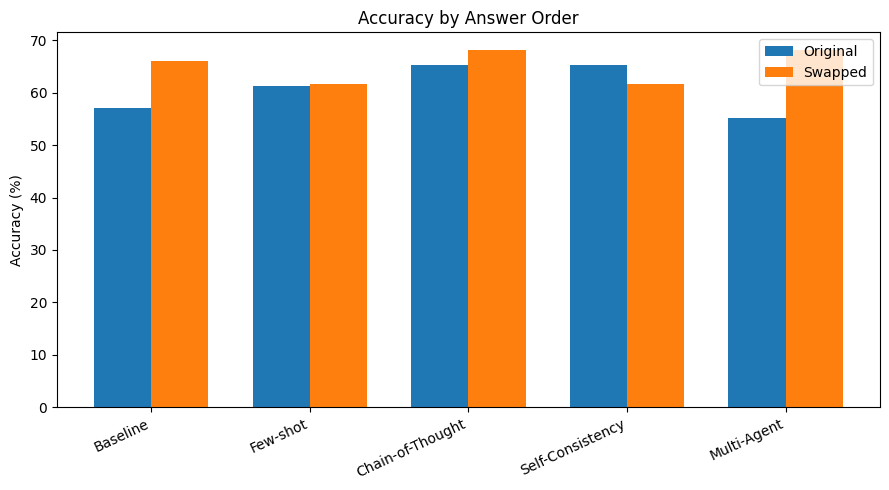

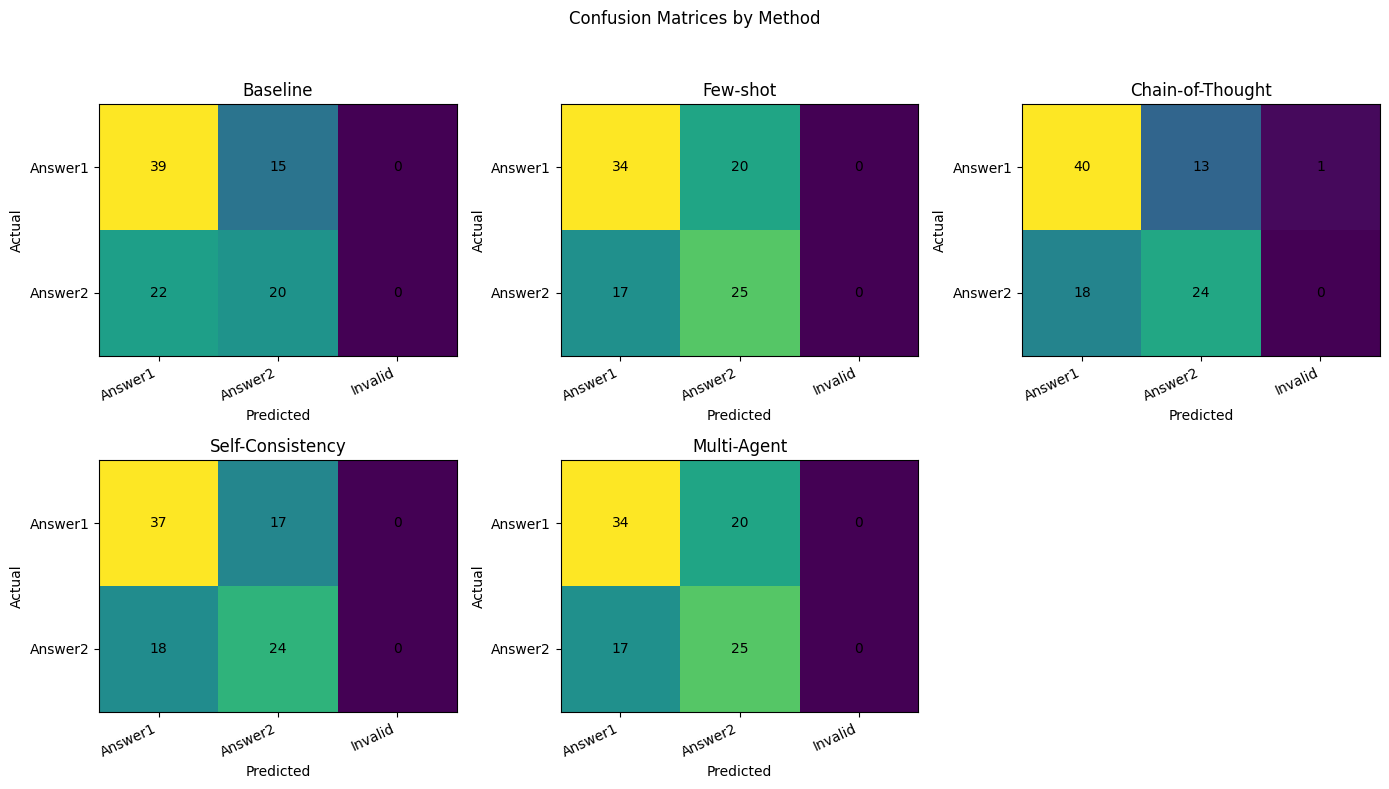

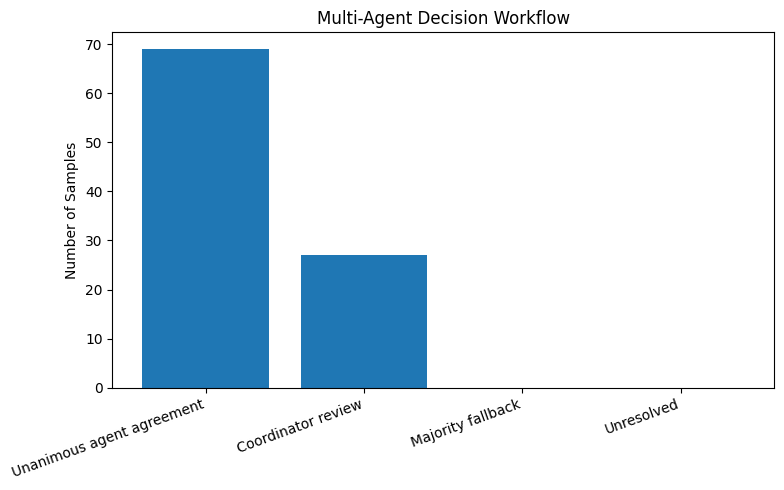

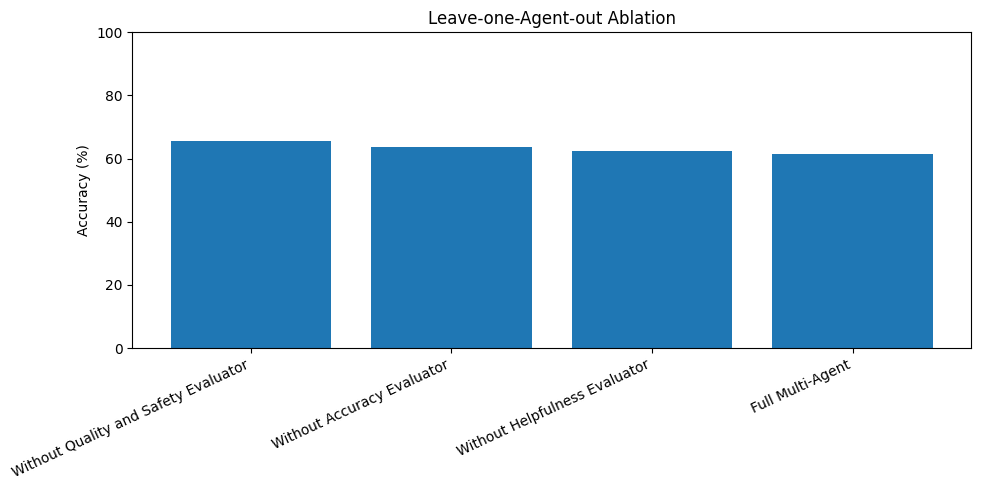

In [27]:
method_order = list(method_dfs.keys())

plot_df = method_comparison_df.set_index("Method").loc[method_order].reset_index()

plt.figure(figsize=(9, 5))
plt.bar(plot_df["Method"], plot_df["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("Human Preference Accuracy by Method")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(plot_df["Method"], plot_df["Average Latency (s)"])
plt.ylabel("Average Latency (seconds)")
plt.title("Average Latency by Method")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("latency_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

if plot_df["Total Tokens"].notna().any():
    plt.figure(figsize=(9, 5))
    plt.bar(plot_df["Method"], plot_df["Total Tokens"])
    plt.ylabel("Total Tokens")
    plt.title("Total Token Usage by Method")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig("token_usage_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()

plt.figure(figsize=(8, 5))
label_offsets = [(5, 5), (5, 14), (5, -12), (5, 5), (5, 14)]

for index, (_, row) in enumerate(plot_df.iterrows()):
    plt.scatter(
        row["Average Latency (s)"],
        row["Accuracy (%)"]
    )
    plt.annotate(
        row["Method"],
        (
            row["Average Latency (s)"],
            row["Accuracy (%)"]
        ),
        xytext=label_offsets[index],
        textcoords="offset points"
    )

plt.xlabel("Average Latency (seconds)")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy-Latency Trade-off")
plt.tight_layout()
plt.savefig("accuracy_latency_tradeoff.png", dpi=200, bbox_inches="tight")
plt.show()

order_plot = order_results.set_index("Method").loc[method_order].reset_index()
x = np.arange(len(order_plot))
width = 0.36

plt.figure(figsize=(9, 5))
plt.bar(
    x - width / 2,
    order_plot["Original Accuracy (%)"],
    width,
    label="Original"
)
plt.bar(
    x + width / 2,
    order_plot["Swapped Accuracy (%)"],
    width,
    label="Swapped"
)
plt.xticks(x, order_plot["Method"], rotation=25, ha="right")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy by Answer Order")
plt.legend()
plt.tight_layout()
plt.savefig("answer_order_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for index, method in enumerate(method_order):
    matrix = (
        confusion_results[
            confusion_results["Method"] == method
        ]
        .pivot(
            index="Actual",
            columns="Predicted",
            values="Count"
        )
        .reindex(
            index=["Answer1", "Answer2"],
            columns=["Answer1", "Answer2", "Unparseable"],
            fill_value=0
        )
    )

    image = axes[index].imshow(matrix.to_numpy(), aspect="auto")
    axes[index].set_title(method)
    axes[index].set_xticks(range(3))
    axes[index].set_xticklabels(
        ["Answer1", "Answer2", "Invalid"],
        rotation=25,
        ha="right"
    )
    axes[index].set_yticks(range(2))
    axes[index].set_yticklabels(["Answer1", "Answer2"])
    axes[index].set_xlabel("Predicted")
    axes[index].set_ylabel("Actual")

    for row_index in range(2):
        for col_index in range(3):
            axes[index].text(
                col_index,
                row_index,
                int(matrix.iloc[row_index, col_index]),
                ha="center",
                va="center"
            )


axes[-1].axis("off")
fig.suptitle("Confusion Matrices by Method")
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig("confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
decision_order = [
    "Unanimous agent agreement",
    "Coordinator review",
    "Majority fallback",
    "Unresolved"
]
decision_plot = decision_counts.reindex(
    decision_order,
    fill_value=0
)
plt.bar(decision_plot.index, decision_plot.values)
plt.ylabel("Number of Samples")
plt.title("Multi-Agent Decision Workflow")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("agent_workflow_decisions.png", dpi=200, bbox_inches="tight")
plt.show()

ablation_plot = ablation_results.sort_values(
    "Overall Accuracy (%)",
    ascending=False
)

plt.figure(figsize=(10, 5))
plt.bar(
    ablation_plot["Method"],
    ablation_plot["Overall Accuracy (%)"]
)
plt.ylabel("Accuracy (%)")
plt.title("Leave-one-Agent-out Ablation")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("agent_ablation_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.9 Export Final Results

In [28]:
OUTPUT_DIR = Path("task2_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

export_tables = {
    "baseline_results.csv": baseline_df,
    "few_shot_results.csv": few_shot_df,
    "cot_results.csv": cot_df,
    "self_consistency_results.csv": sc_df,
    "multi_agent_results.csv": multi_agent_df,
    "method_comparison.csv": method_comparison_df,
    "agent_workflow_summary.csv": workflow_summary,
    "agent_decision_sources.csv": decision_counts.rename_axis("Decision Source").reset_index(name="Samples"),
    "prompt_design_summary.csv": pd.DataFrame([
        {"Method": "Baseline", "Technique": "Zero-shot prompting", "Purpose": "Establish a direct-prompt reference."},
        {"Method": "Few-shot", "Technique": "Few-shot prompting", "Purpose": "Provide four labeled demonstrations balanced across preference classes."},
        {"Method": "Chain-of-Thought", "Technique": "Structured reasoning prompt", "Purpose": "Encourage explicit comparison across relevance, helpfulness, correctness and safety."},
        {"Method": "Self-Consistency", "Technique": "Self-consistency", "Purpose": "Aggregate five independent sampled judgments."},
        {"Method": "Multi-Agent", "Technique": "Role-based agents with conditional coordination", "Purpose": "Combine specialized evaluations and escalate disagreements to a Coordinator."}
    ]),
    "paired_error_analysis.csv": paired_error_summary,
    "overall_statistical_tests.csv": overall_tests,
    "pairwise_statistical_results.csv": pairwise_results,
    "efficiency_pareto_analysis.csv": efficiency_df,
    "ablation_study_results.csv": ablation_results,
    "ablation_predictions.csv": ablation_predictions,
    "answer_order_bias_analysis.csv": order_results,
    "classification_performance_metrics.csv": classification_results,
    "classification_per_class_metrics.csv": per_class_results,
    "classification_confusion_matrices.csv": confusion_results,
    "representative_cases.csv": representative_cases,
    "data_split_metadata.csv": data_split_metadata
}

for filename, table in export_tables.items():
    table.to_csv(
        OUTPUT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

all_predictions = baseline_df[
    ["sample_id", "human_preference"]
].copy()

for method, results_df in method_dfs.items():
    method_predictions = results_df[
        ["sample_id", "prediction", "correct"]
    ].rename(columns={
        "prediction": f"{method} Prediction",
        "correct": f"{method} Correct"
    })

    all_predictions = all_predictions.merge(
        method_predictions,
        on="sample_id",
        how="inner",
        validate="one_to_one"
    )

all_predictions.to_csv(
    OUTPUT_DIR / "all_method_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

experiment_settings = {
    "task": "Task 2: LLMs for AI Feedback",
    "model": MODEL_NAME,
    "base_temperature": BASE_TEMPERATURE,
    "self_consistency_temperature": SC_TEMPERATURE,
    "self_consistency_votes": N_SC_VOTES,
    "coordinator_temperature": BASE_TEMPERATURE,
    "original_samples": len(data),
    "few_shot_samples": len(few_shot_examples),
    "evaluation_samples": len(test_data),
    "answer_order_seed": RANDOM_SEED,
    "few_shot_seed": FEW_SHOT_SEED,
    "few_shot_examples_per_displayed_preference_class": N_FEW_SHOT // 2,
    "data_url": DATA_URL,
    "evaluation_sample_ids": reference_ids,
    "evaluation_answer_order_counts": {
        key: int(value)
        for key, value in order_distribution.items()
    },
    "agent_roles": [
        {"name": name, "focus": focus}
        for name, focus in agent_roles
    ],
    "answer_order_full_dataset": {
        "swapped": int(sum(swap_flags)),
        "original": int(len(swap_flags) - sum(swap_flags))
    },
    "few_shot_sample_ids": [
        int(index + 1)
        for index in few_shot_indices
    ],
    "methods": list(method_dfs.keys()),
    "multi_agent_workflow": (
        "Three independent evaluators; unanimous decisions are accepted. "
        "Disagreement or invalid output triggers Coordinator review. "
        "If Coordinator output is invalid, a valid two-vote majority is used."
    )
}

with (OUTPUT_DIR / "experiment_settings.json").open(
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        experiment_settings,
        file,
        ensure_ascii=False,
        indent=2
    )

for image_name in [
    "accuracy_comparison.png",
    "latency_comparison.png",
    "token_usage_comparison.png",
    "accuracy_latency_tradeoff.png",
    "answer_order_comparison.png",
    "confusion_matrices.png",
    "agent_workflow_decisions.png",
    "agent_ablation_comparison.png"
]:
    image_path = Path(image_name)
    if image_path.exists():
        image_path.replace(OUTPUT_DIR / image_name)

zip_path = Path("task2_results.zip")

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for file_path in OUTPUT_DIR.iterdir():
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.name
            )

print("Final results exported to:", OUTPUT_DIR.resolve())
print("ZIP archive:", zip_path.resolve())
print("Exported files:", len(list(OUTPUT_DIR.iterdir())))

Final results exported to: /content/task2_results
ZIP archive: /content/task2_results.zip
Exported files: 31
